### PM - 2.5

In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "sensors").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Could not find project root.")


project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.visualization.time_series_plotter import TimeSeriesPlotter
from src.time_series.time_series_sampler import resample_and_align
from src.time_series.time_series_comparison_metrics import (
    compute_rmse,
    compute_correlation_coefficient,
    compute_linear_fit,
    compute_mae,
)

SENSORS_DIR = project_root / "data" / "sensors"
our_data_path = SENSORS_DIR / "boston_carter_field" / "boston_carter_field.csv"
reference_data_path = SENSORS_DIR / "boston_carter_field_reference" / "MOD-00157-CarterField.csv"

data_1 = pd.read_csv(our_data_path)
reference_data = pd.read_csv(reference_data_path)

aligned = resample_and_align(
    data_1,
    reference_data,
    time_column="timestamp",
    variable_name="pm25",
    sampling_interval="0.1min",
)

print(f"Aligned rows: {len(aligned)}")
aligned.head()

Correlation Coefficient between our sensor and reference sensor PM2.5: 0.83
MAE between our sensor and reference sensor PM2.5: 3.43


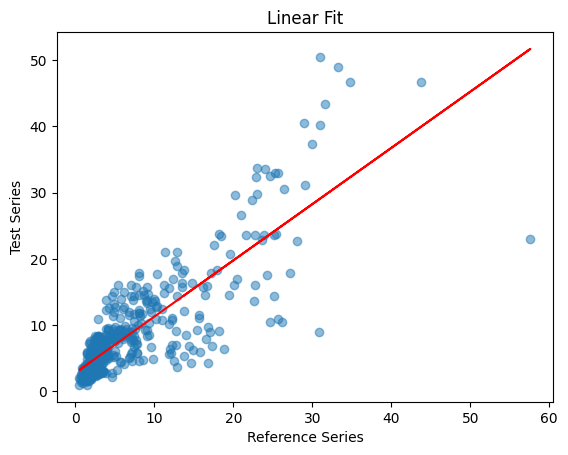

Linear fit results: slope=0.85, intercept=2.83, r_value=0.83, r_squared=0.69


In [2]:
time_series_1 = list(aligned["pm25_1_aligned"])
time_series_2 = list(aligned["pm25_2"])

correlation_coefficient = compute_correlation_coefficient(time_series_1, time_series_2)
print(f"Correlation Coefficient between our sensor and reference sensor PM2.5: {correlation_coefficient:.2f}")

mae = compute_mae(time_series_1, time_series_2)
print(f"MAE between our sensor and reference sensor PM2.5: {mae:.2f}")

linear_fit = compute_linear_fit(time_series_1, time_series_2, plot =True)
print(f"Linear fit results: slope={linear_fit['slope']:.2f}, intercept={linear_fit['intercept']:.2f}, r_value={linear_fit['r_value']:.2f}, r_squared={linear_fit['r_squared']:.2f}")

### Temperature

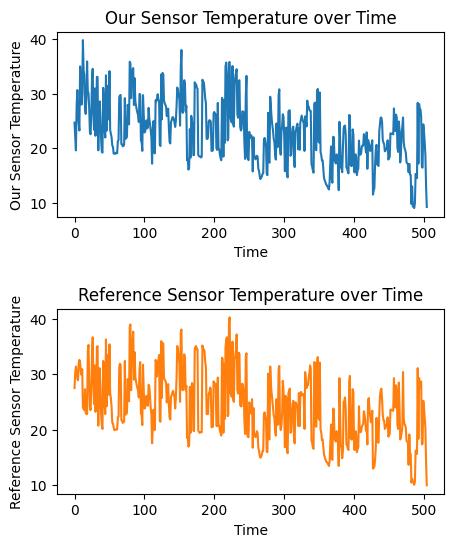

In [3]:
reference_data["temperature"] = reference_data["temp"]
aligned = resample_and_align(
    data_1,
    reference_data,
    time_column = "timestamp",
    variable_name = "temperature",
    sampling_interval = "0.1min",
    
)


plotter = TimeSeriesPlotter()
axes = plotter.plot(
    time_axis_data = list(range(0, len(aligned))),
    time_series_data = [list(aligned["temperature_1_aligned"]), list(aligned["temperature_2"])],
    x_label = "Time",
    y_labels = ["Our Sensor Temperature", "Reference Sensor Temperature"],
    titles = ["Our Sensor Temperature over Time", "Reference Sensor Temperature over Time"],
    row_spacing = 0.5
    
)
import matplotlib.pyplot as plt
#axes[0].set_ylim(0,60)
#axes[1].set_ylim(0,60)
plt.savefig(figures_path/"temperature_time_series_comparison.png", dpi=300)

Correlation Coefficient between our sensor and reference sensor Temperature: 0.95
MAE between our sensor and reference sensor Temperature: 1.55


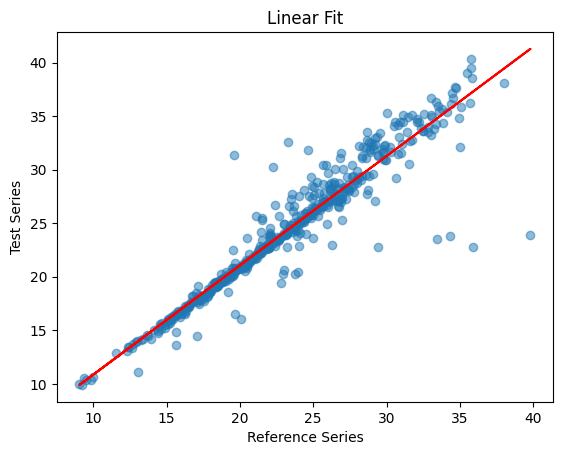

Linear fit results: slope=1.02, intercept=0.64, r_value=0.95, r_squared=0.90


In [4]:
time_series_1 = list(aligned["temperature_1_aligned"])
time_series_2 = list(aligned["temperature_2"])

correlation_coefficient = compute_correlation_coefficient(time_series_1, time_series_2)
print(f"Correlation Coefficient between our sensor and reference sensor Temperature: {correlation_coefficient:.2f}")
mae = compute_mae(time_series_1, time_series_2)
print(f"MAE between our sensor and reference sensor Temperature: {mae:.2f}")

linear_fit = compute_linear_fit(time_series_1, time_series_2, plot =True)
print(f"Linear fit results: slope={linear_fit['slope']:.2f}, intercept={linear_fit['intercept']:.2f}, r_value={linear_fit['r_value']:.2f}, r_squared={linear_fit['r_squared']:.2f}")

### Relative Humidity

Index(['timestamp', 'timestamp_local', 'rh', 'temp', 'lat', 'lon', 'pm1',
       'pm25', 'pm10', 'temperature', 'relative_humidity'],
      dtype='object')


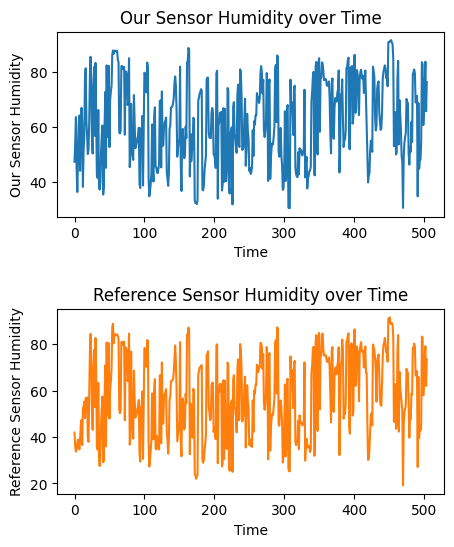

In [5]:
reference_data["relative_humidity"] = reference_data["rh"]
aligned = resample_and_align(
    data_1,
    reference_data,
    time_column = "timestamp",
    variable_name = "relative_humidity",
    sampling_interval = "0.1min"
)


plotter = TimeSeriesPlotter()
axes = plotter.plot(
    time_axis_data = list(range(0, len(aligned))),
    time_series_data = [list(aligned["relative_humidity_1_aligned"]), list(aligned["relative_humidity_2"])],
    x_label = "Time",
    y_labels = ["Our Sensor Humidity", "Reference Sensor Humidity"],
    titles = ["Our Sensor Humidity over Time", "Reference Sensor Humidity over Time"],
    row_spacing = 0.5
    
)



plt.savefig(figures_path/"humidity_time_series_comparison.png", dpi=300)
print(reference_data.keys())


Correlation Coefficient between our sensor and reference sensor Humidity: 0.97
MAE between our sensor and reference sensor Humidity: 4.53


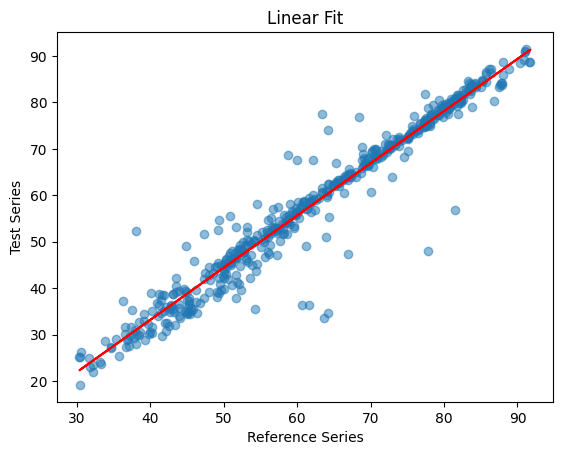

Linear fit results: slope=1.12, intercept=-11.68, r_value=0.97, r_squared=0.95


In [6]:
# Let's do some correlation 

time_series_1 = list(aligned["relative_humidity_1_aligned"])
time_series_2 = list(aligned["relative_humidity_2"])
correlation_coefficient = compute_correlation_coefficient(time_series_1, time_series_2)
print(f"Correlation Coefficient between our sensor and reference sensor Humidity: {correlation_coefficient:.2f}")
mae = compute_mae(time_series_1, time_series_2)
print(f"MAE between our sensor and reference sensor Humidity: {mae:.2f}")
linear_fit = compute_linear_fit(time_series_1, time_series_2, plot =True)
print(f"Linear fit results: slope={linear_fit['slope']:.2f}, intercept={linear_fit['intercept']:.2f}, r_value={linear_fit['r_value']:.2f}, r_squared={linear_fit['r_squared']:.2f}")